# Hospital Length-of-Stay Range Prediction

## 1. Problem Statement

Analyze the supplied hospital records and build a machine learning model that predicts a patient’s length-of-stay category from hospital, admission, and patient information.

## 2. Business Objective

A hospital can use stay-range estimates to support early bed and staffing planning. This notebook compares a small number of classification models and identifies the features most associated with their predictions. Model output should be considered a planning aid and reviewed alongside clinical judgment and operational information.

## 3. Dataset Description

The dataset contains hospital and patient admission details. The target column `Stay` is recorded as duration ranges (for example, `0-10`, `21-30`, and `More than 100 Days`). Therefore, this notebook predicts a stay range, not an exact number of days. The original `Nov-20` label is standardized to `11-20` for both `Stay` and `Age`.

### Main columns

- Hospital and location: `Hospital_code`, `Hospital_type_code`, `City_Code_Hospital`, `Hospital_region_code`.
- Admission and care: `Department`, `Ward_Type`, `Ward_Facility_Code`, `Bed_Grade`, `Type_of_Admission`, `Severity_of_Illness`.
- Patient and facilities: `Age`, `Visitors_with_Patient`, `Available_Extra_Rooms_in_Hospital`.
- Deposit: `Admission_Deposit`.
- Target: `Stay`, the length-of-stay range.

`case_id` and `patientid` are identifiers; they are not used as predictive features.

## 4. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             ConfusionMatrixDisplay)

## 5. Data Loading

In [2]:
data = pd.read_csv('HealthCareAnalytics.csv')
data.head()

,case_id,Hospital_code,Hospital_type_code,City_Code_Hospital,Hospital_region_code,Available_Extra_Rooms_in_Hospital,Department,Ward_Type,Ward_Facility_Code,Bed_Grade,patientid,City_Code_Patient,Type_of_Admission,Severity_of_Illness,Visitors_with_Patient,Age,Admission_Deposit,Stay
0,1,8,c,3,Z,3,radiotherapy,R,F,2.0,31397,7.0,Emergency,Extreme,2,51-60,4911,0-10
1,2,2,c,5,Z,2,radiotherapy,S,F,2.0,31397,7.0,Trauma,Extreme,2,51-60,5954,41-50
2,3,10,e,1,X,2,anesthesia,S,E,2.0,31397,7.0,Trauma,Extreme,2,51-60,4745,31-40
3,4,26,b,2,Y,2,radiotherapy,R,D,2.0,31397,7.0,Trauma,Extreme,2,51-60,7272,41-50
4,5,26,b,2,Y,2,radiotherapy,S,D,2.0,31397,7.0,Trauma,Extreme,2,51-60,5558,41-50


## 6. Initial Data Exploration

In [3]:
data.shape

(318438, 18)

In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 318438 entries, 0 to 318437
Data columns (total 18 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   case_id                            318438 non-null  int64  
 1   Hospital_code                      318438 non-null  int64  
 2   Hospital_type_code                 318438 non-null  object 
 3   City_Code_Hospital                 318438 non-null  int64  
 4   Hospital_region_code               318438 non-null  object 
 5   Available_Extra_Rooms_in_Hospital  318438 non-null  int64  
 6   Department                         318438 non-null  object 
 7   Ward_Type                          318438 non-null  object 
 8   Ward_Facility_Code                 318438 non-null  object 
 9   Bed_Grade                          318325 non-null  float64
 10  patientid                          318438 non-null  int64  
 11  City_Code_Patient                  3139

In [5]:
data.describe()

,case_id,Hospital_code,City_Code_Hospital,Available_Extra_Rooms_in_Hospital,Bed_Grade,patientid,City_Code_Patient,Visitors_with_Patient,Admission_Deposit
count,318438.000000,318438.000000,318438.000000,318438.000000,318325.000000,318438.000000,313906.000000,318438.000000,318438.000000
mean,159219.500000,18.318841,4.771717,3.197627,2.625807,65747.579472,7.251859,3.284099,4880.749392
std,91925.276847,8.633755,3.102535,1.168171,0.873146,37979.936440,4.745266,1.764061,1086.776254
min,1.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,0.000000,1800.000000
25%,79610.250000,11.000000,2.000000,2.000000,2.000000,32847.000000,4.000000,2.000000,4186.000000
50%,159219.500000,19.000000,5.000000,3.000000,3.000000,65724.500000,8.000000,3.000000,4741.000000
75%,238828.750000,26.000000,7.000000,4.000000,3.000000,98470.000000,8.000000,4.000000,5409.000000
max,318438.000000,32.000000,13.000000,24.000000,4.000000,131624.000000,38.000000,32.000000,11008.000000


In [6]:
data['Stay'].value_counts()

Stay
21-30                 87491
Nov-20                78139
31-40                 55159
51-60                 35018
0-10                  23604
41-50                 11743
71-80                 10254
More than 100 Days     6683
81-90                  4838
91-100                 2765
61-70                  2744
Name: count, dtype: int64

## 7. Data Cleaning

In [7]:
data.isnull().sum()

case_id                                 0
Hospital_code                           0
Hospital_type_code                      0
City_Code_Hospital                      0
Hospital_region_code                    0
Available_Extra_Rooms_in_Hospital       0
Department                              0
Ward_Type                               0
Ward_Facility_Code                      0
Bed_Grade                             113
patientid                               0
City_Code_Patient                    4532
Type_of_Admission                       0
Severity_of_Illness                     0
Visitors_with_Patient                   0
Age                                     0
Admission_Deposit                       0
Stay                                    0
dtype: int64

In [8]:
data.duplicated().sum()

np.int64(0)

There are missing values in `Bed_Grade` and `City_Code_Patient`. The preprocessing step below fills missing numeric values with the median and categorical values with the most common value, using training data only. The provided file has a unique `case_id`; identifier columns are excluded from modeling. Duplicate counts are inspected, and records are retained because repeated feature patterns can represent distinct admissions.

In [9]:
# Standardize the range label that appears as 'Nov-20' in the source file.
data['Stay'] = data['Stay'].replace('Nov-20', '11-20')
data['Age'] = data['Age'].replace('Nov-20', '11-20')

print('Shape:', data.shape)
print('Missing values by column:')
print(data.isnull().sum()[data.isnull().sum() > 0])
print('Exact duplicate rows:', data.duplicated().sum())
print('Stay categories:', sorted(data['Stay'].unique()))

Shape: (318438, 18)
Missing values by column:
Bed_Grade             113
City_Code_Patient    4532
dtype: int64
Exact duplicate rows: 0
Stay categories: ['0-10', '11-20', '21-30', '31-40', '41-50', '51-60', '61-70', '71-80', '81-90', '91-100', 'More than 100 Days']


### Data Cleaning Summary

The source data has missing values in two fields and uses `Nov-20` as a label in the stay and age ranges. The label is normalized to `11-20`. Missing values are handled within the modeling pipeline, avoiding removal of otherwise useful admissions. The `case_id` and `patientid` identifiers are excluded to reduce the risk of learning record-specific patterns.

## 8. Exploratory Data Analysis

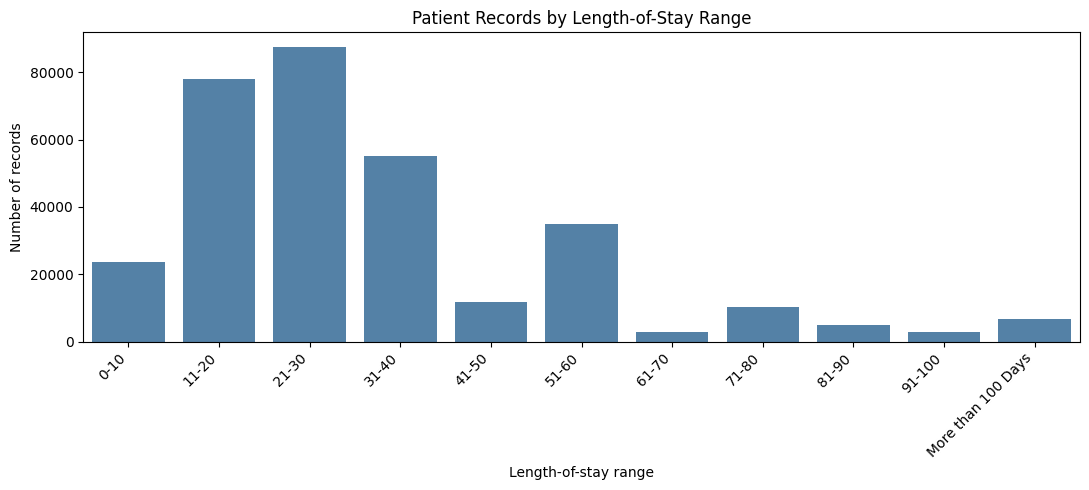

In [10]:
stay_order = ['0-10', '11-20', '21-30', '31-40', '41-50', '51-60',
              '61-70', '71-80', '81-90', '91-100', 'More than 100 Days']
plt.figure(figsize=(11, 5))
sns.countplot(data=data, x='Stay', order=stay_order, color='steelblue')
plt.title('Patient Records by Length-of-Stay Range')
plt.xlabel('Length-of-stay range')
plt.ylabel('Number of records')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

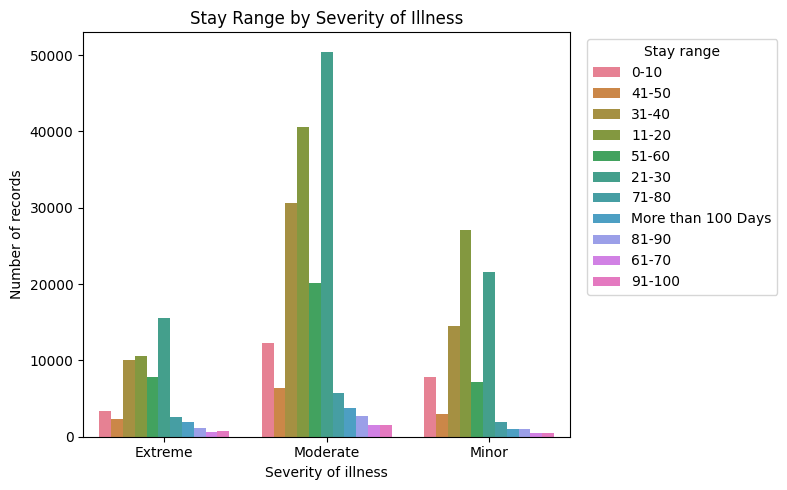

In [11]:
plt.figure(figsize=(8, 5))
sns.countplot(data=data, x='Severity_of_Illness', hue='Stay')
plt.title('Stay Range by Severity of Illness')
plt.xlabel('Severity of illness')
plt.ylabel('Number of records')
plt.legend(title='Stay range', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

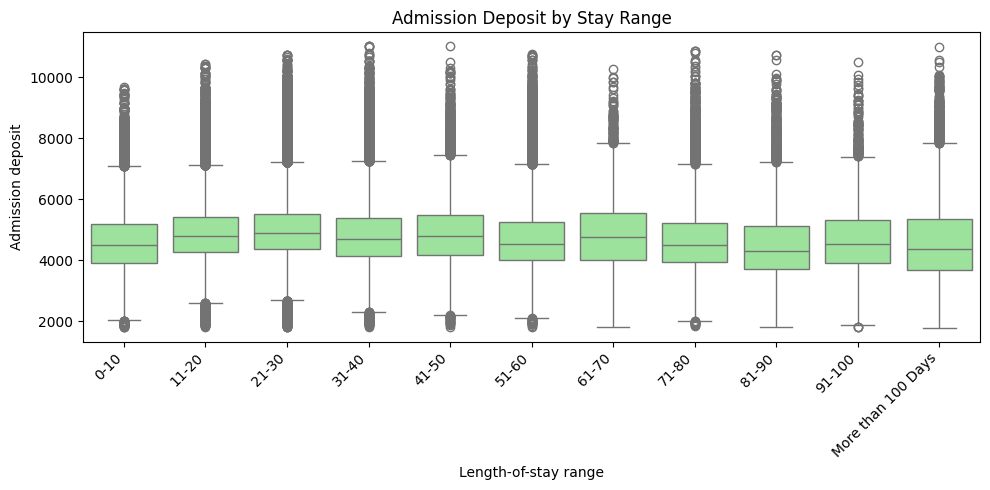

In [12]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=data, x='Stay', y='Admission_Deposit', order=stay_order, color='lightgreen')
plt.title('Admission Deposit by Stay Range')
plt.xlabel('Length-of-stay range')
plt.ylabel('Admission deposit')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

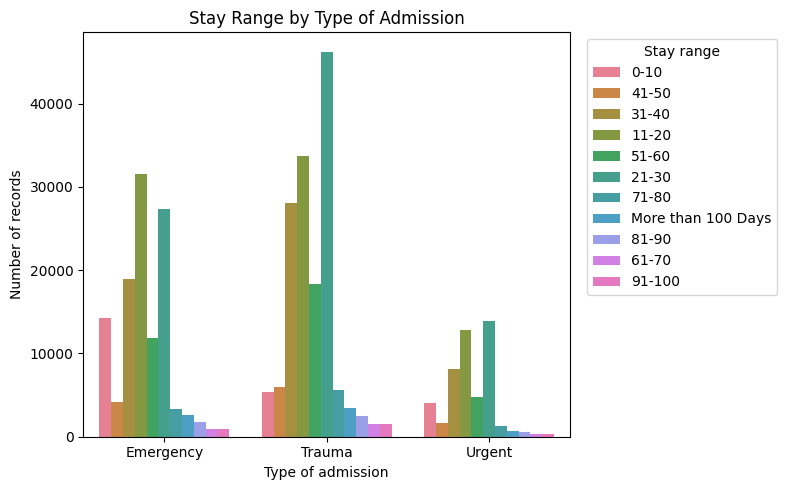

In [13]:
plt.figure(figsize=(8, 5))
sns.countplot(data=data, x='Type_of_Admission', hue='Stay')
plt.title('Stay Range by Type of Admission')
plt.xlabel('Type of admission')
plt.ylabel('Number of records')
plt.legend(title='Stay range', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

The plots show how stay ranges are represented across the dataset and how they vary across admission and severity categories. Category counts are uneven, so model evaluation will include macro F1 in addition to accuracy; macro F1 gives each stay range equal weight.

## 9. Prepare Features

Hospital codes and bed grade are treated as categories rather than continuous measurements. Counts and deposit are numeric. One-hot encoding converts categories into model-ready columns. The preprocessing pipeline imputes missing values and is fitted using only the training split.

In [14]:
target = 'Stay'
identifier_cols = ['case_id', 'patientid']
X = data.drop(columns=[target] + identifier_cols)
y = data[target]

categorical_cols = [
    'Hospital_code', 'Hospital_type_code', 'City_Code_Hospital',
    'Hospital_region_code', 'Department', 'Ward_Type', 'Ward_Facility_Code',
    'Bed_Grade', 'City_Code_Patient', 'Type_of_Admission',
    'Severity_of_Illness', 'Age'
]
numeric_cols = [
    'Available_Extra_Rooms_in_Hospital', 'Visitors_with_Patient',
    'Admission_Deposit'
]

print('Feature columns:', X.shape[1])
print('Target counts:')
print(y.value_counts())

Feature columns: 15
Target counts:
Stay
21-30                 87491
11-20                 78139
31-40                 55159
51-60                 35018
0-10                  23604
41-50                 11743
71-80                 10254
More than 100 Days     6683
81-90                  4838
91-100                 2765
61-70                  2744
Name: count, dtype: int64


In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print('Training rows:', X_train.shape[0])
print('Testing rows:', X_test.shape[0])

Training rows: 254750
Testing rows: 63688


In [16]:
categorical_preparation = Pipeline(steps=[
    ('fill_missing', SimpleImputer(strategy='most_frequent')),
    ('one_hot', OneHotEncoder(handle_unknown='ignore'))
])
numeric_preparation = Pipeline(steps=[
    ('fill_missing', SimpleImputer(strategy='median'))
])

preprocessor = ColumnTransformer(transformers=[
    ('categories', categorical_preparation, categorical_cols),
    ('numbers', numeric_preparation, numeric_cols)
])

## 10. Model Evaluation

Two tree-based classifiers are compared: a single Decision Tree and a Random Forest. Accuracy measures the overall share of correct predictions. Macro F1 averages the F1-score across stay ranges, giving less common ranges equal importance in the comparison. Weighted F1 accounts for the number of records in each range.

## 11. Decision Tree Model

In [17]:
decision_tree = Pipeline(steps=[
    ('prepare', preprocessor),
    ('model', DecisionTreeClassifier(class_weight='balanced', random_state=42))
])
decision_tree.fit(X_train, y_train)
pred_tree = decision_tree.predict(X_test)

## 12. Random Forest Model

In [18]:
random_forest = Pipeline(steps=[
    ('prepare', preprocessor),
    ('model', RandomForestClassifier(
        n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1
    ))
])
random_forest.fit(X_train, y_train)
pred_forest = random_forest.predict(X_test)

## 13. Model Comparison

In [19]:
model_comparison = pd.DataFrame({
    'Model': ['Decision Tree', 'Random Forest'],
    'Accuracy': [accuracy_score(y_test, pred_tree), accuracy_score(y_test, pred_forest)],
    'Macro F1': [f1_score(y_test, pred_tree, average='macro'), f1_score(y_test, pred_forest, average='macro')],
    'Weighted F1': [f1_score(y_test, pred_tree, average='weighted'), f1_score(y_test, pred_forest, average='weighted')]
})
model_comparison.round(3)

,Model,Accuracy,Macro F1,Weighted F1
0,Decision Tree,0.294,0.216,0.296
1,Random Forest,0.375,0.263,0.359


In [20]:
print('Decision Tree classification report')
print(classification_report(y_test, pred_tree, labels=stay_order, zero_division=0))
print('Random Forest classification report')
print(classification_report(y_test, pred_forest, labels=stay_order, zero_division=0))

Decision Tree classification report
                    precision    recall  f1-score   support

              0-10       0.19      0.20      0.19      4721
             11-20       0.35      0.33      0.34     15628
             21-30       0.39      0.37      0.38     17498
             31-40       0.25      0.24      0.25     11032
             41-50       0.06      0.07      0.06      2349
             51-60       0.30      0.31      0.31      7004
             61-70       0.03      0.04      0.03       549
             71-80       0.14      0.16      0.14      2051
             81-90       0.22      0.24      0.23       967
            91-100       0.09      0.11      0.10       553
More than 100 Days       0.34      0.36      0.35      1336

          accuracy                           0.29     63688
         macro avg       0.21      0.22      0.22     63688
      weighted avg       0.30      0.29      0.30     63688

Random Forest classification report
                    preci

Selected candidate based on macro F1: Random Forest


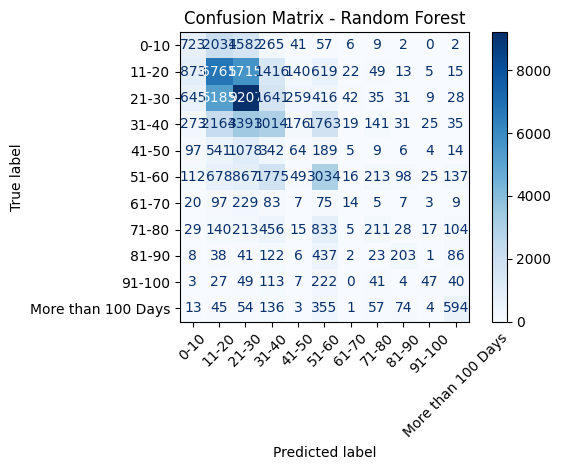

In [21]:
best_name = model_comparison.sort_values('Macro F1', ascending=False).iloc[0]['Model']
best_predictions = pred_tree if best_name == 'Decision Tree' else pred_forest
print('Selected candidate based on macro F1:', best_name)
ConfusionMatrixDisplay.from_predictions(
    y_test, best_predictions, labels=stay_order, xticks_rotation=45,
    cmap='Blues', normalize=None
)
plt.title(f'Confusion Matrix - {best_name}')
plt.tight_layout()
plt.show()

## 14. Feature Importance

The Random Forest feature-importance chart summarizes which encoded inputs contributed most to the fitted forest. These scores are useful for follow-up analysis, but they do not show that a feature causes a longer or shorter stay.

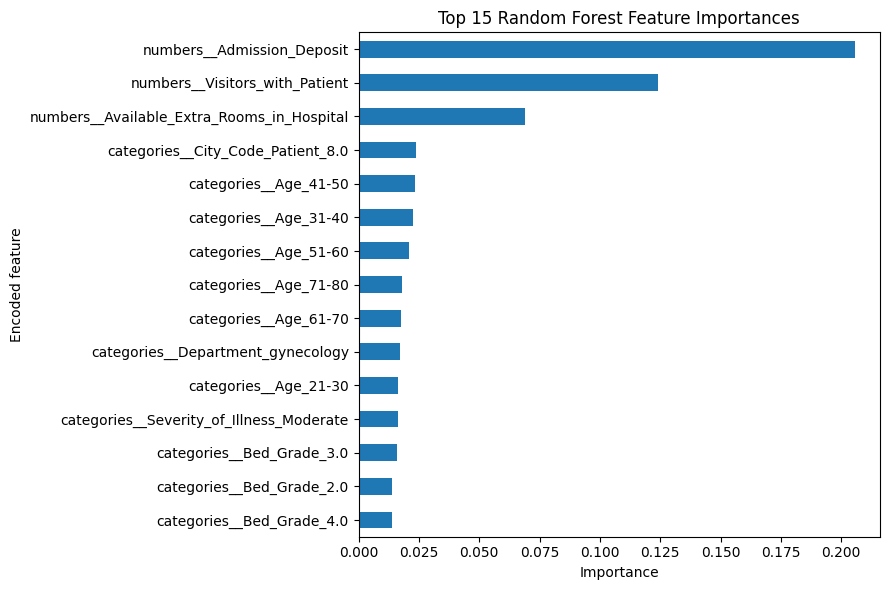

numbers__Admission_Deposit                    0.205824
numbers__Visitors_with_Patient                0.124035
numbers__Available_Extra_Rooms_in_Hospital    0.068994
categories__City_Code_Patient_8.0             0.023569
categories__Age_41-50                         0.023415
categories__Age_31-40                         0.022696
categories__Age_51-60                         0.020977
categories__Age_71-80                         0.017996
categories__Age_61-70                         0.017494
categories__Department_gynecology             0.017232
categories__Age_21-30                         0.016425
categories__Severity_of_Illness_Moderate      0.016381
categories__Bed_Grade_3.0                     0.015820
categories__Bed_Grade_2.0                     0.014028
categories__Bed_Grade_4.0                     0.013966
dtype: float64

In [24]:
rf_model = random_forest.named_steps['model']
encoded_names = random_forest.named_steps['prepare'].get_feature_names_out()
feature_importance = pd.Series(rf_model.feature_importances_, index=encoded_names).sort_values(ascending=False)
top_features = feature_importance.head(15).sort_values()
top_features.plot(kind='barh', figsize=(9, 6))
plt.title('Top 15 Random Forest Feature Importances')
plt.xlabel('Importance')
plt.ylabel('Encoded feature')
plt.tight_layout()
plt.show()
feature_importance.head(15)

## 15. Business Use and Production Recommendation

A stay-range estimate could help hospital teams plan bed availability, staffing, and expected resource demand. The feature-importance ranking can guide further review of which admission and facility details are associated with the predictions. The model should be used as a planning aid, with human review, rather than as a clinical decision tool. The model with the stronger macro F1 is selected as the candidate for additional validation. Before production, assess performance by hospital and patient group, test on more recent admissions, and review the impact of prediction errors with hospital staff.

## 16. Challenges and Techniques Used

- **Target values are ranges:** the data does not provide exact days for each patient. Classification predicts the supplied range; exact-day regression would need exact length-of-stay values.
- **Missing values:** `Bed_Grade` and `City_Code_Patient` have missing entries. Median/mode imputation in a pipeline keeps records while learning fill values from the training data.
- **Mixed data types:** codes and labels represent categories, while rooms, visitors, and deposit are numeric. One-hot encoding and separate imputers handle these types simply.
- **Uneven class sizes:** some stay ranges have fewer records. Stratified splitting preserves class proportions and macro F1 highlights performance on smaller ranges.
- **Identifier leakage risk:** `case_id` and `patientid` identify records or people rather than generalizable admission characteristics, so they are excluded from model inputs.
- **Healthcare context:** predictions may be affected by clinical factors absent from the dataset. Results need careful validation and must not replace clinical judgment.

## 17. Conclusion

In [23]:
comparison = model_comparison.sort_values('Macro F1', ascending=False).reset_index(drop=True)
print(comparison.round(3))
print(f"\nCandidate model: {comparison.loc[0, 'Model']} based on the higher macro F1 on this held-out split.")
print('This result predicts stay ranges, not exact days. Validate with newer data and clinical/operational review before any production use.')

           Model  Accuracy  Macro F1  Weighted F1
0  Random Forest     0.375     0.263        0.359
1  Decision Tree     0.294     0.216        0.296

Candidate model: Random Forest based on the higher macro F1 on this held-out split.
This result predicts stay ranges, not exact days. Validate with newer data and clinical/operational review before any production use.


The notebook evaluates two approachable classification models for the supplied stay-range label and reports accuracy, macro F1, weighted F1, class-level scores, and a confusion matrix. The leading model is a candidate for further validation only. The current target categories do not support an exact day prediction, and external clinical validation is needed before operational use.